# Digital Image Processing Lab — Lab Task 05
## Spatial Filtering and Convolution

| | |
|---|---|
| **Name** | Ubaidullah |
| **Roll No** | 2024-SE-17 |
| **Session / Semester** | 2024-28 (SE) / Fifth |
| **Instructor** | Engr. Fahad Nisar |
| **University / Department** | The University of Azad Jammu and Kashmir — Department of Software Engineering |

**Rules followed throughout:** R1 same-size output, reflect padding · R2 float64 maths, round + clip to uint8 only at the end · R3 smoothing weights sum to 1 · R4 odd kernel sizes 3/5/7 · R5 noise with `seed=5` · R6 every filtered image is judged against the **clean original**.

## 1. Setup and the three test images

In [1]:
import os, math
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from skimage import data
from skimage.metrics import peak_signal_noise_ratio as psnr
from IPython.display import display, Markdown

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    for r in rows:
        lines.append("| " + " | ".join(str(c) for c in r) + " |")
    display(Markdown("\n".join(lines)))

# camera and coins are already grayscale; chelsea is colour -> grayscale
chelsea_rgb = data.chelsea()
chelsea = cv.cvtColor(chelsea_rgb, cv.COLOR_RGB2GRAY)
ORIGINALS = {"camera": data.camera(), "coins": data.coins(), "chelsea": chelsea}
for img in ORIGINALS.values():
    img.setflags(write=False)                         # keep the originals unchanged

for name, img in ORIGINALS.items():
    print(f"{name:8s} shape={img.shape}  dtype={img.dtype}  min={img.min()}  max={img.max()}")
print("OpenCV", cv.__version__, "| NumPy", np.__version__)

camera   shape=(512, 512)  dtype=uint8  min=0  max=255
coins    shape=(303, 384)  dtype=uint8  min=1  max=252
chelsea  shape=(300, 451)  dtype=uint8  min=4  max=194
OpenCV 5.0.0 | NumPy 2.5.4


## 2. `conv2d_loop` — 2-D convolution from first principles
Steps: **flip** the kernel in both directions (true convolution, not correlation) → **reflect-pad** the image by `k//2` on every side → for every output pixel take the **weighted sum** of its window → return **float64** of the same size as the input (R1, R2).
Reflect padding without repeating the edge pixel is NumPy `mode="reflect"` (= OpenCV `BORDER_REFLECT_101`).

In [2]:
def check_ksize(k):
    """R4: kernel size must be one of the odd sizes 3, 5, 7."""
    if isinstance(k, bool) or not isinstance(k, (int, np.integer)) or k not in (3, 5, 7):
        raise ValueError(f"Kernel size must be 3, 5 or 7 (odd), got {k!r}.")
    return int(k)

def to_uint8(x):
    """R2: convert to uint8 only at the end, with round and clip to 0-255."""
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)

def conv2d_loop(img, kernel):
    img = np.asarray(img, dtype=np.float64)                    # R2: calculate in float64
    kernel = np.asarray(kernel, dtype=np.float64)
    if img.ndim != 2 or kernel.ndim != 2:
        raise ValueError("img and kernel must both be 2-D arrays.")
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError(f"Kernel dimensions must be odd, got {kernel.shape}.")
    flipped = kernel[::-1, ::-1]                               # true convolution: flip both axes
    ph, pw = kh // 2, kw // 2
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect") # reflect padding (R1)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for i in range(H):                                         # nested pixel loops
        for j in range(W):
            out[i, j] = np.sum(padded[i:i + kh, j:j + kw] * flipped)
    return out                                                 # same size as input, float64

# tiny sanity test with a non-symmetric kernel: convolving a single bright pixel stamps the FLIPPED kernel
impulse = np.zeros((5, 5)); impulse[2, 2] = 1
k_demo = np.arange(1, 10, dtype=float).reshape(3, 3)
print("kernel:\n", k_demo)
print("response to an impulse (a convolution outputs the kernel rotated by 180 degrees):\n", conv2d_loop(impulse, k_demo)[1:4, 1:4])

kernel:
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]
response to an impulse (a convolution outputs the kernel rotated by 180 degrees):
 [[1. 2. 3.]
 [4. 5. 6.]
 [7. 8. 9.]]


## 3. Verifying `conv2d_loop` against OpenCV
OpenCV's `cv.filter2D` computes **correlation**, so to obtain a convolution we hand it the flipped kernel. An **asymmetric** kernel is used so that a missing flip would show up as a large error. All calculation is in float64 and borders use `BORDER_REFLECT_101`.

In [3]:
import time
cam = ORIGINALS["camera"]
asym = np.array([[1, 2, 0], [4, 5, -1], [0, -3, 2]], dtype=np.float64)     # asymmetric on purpose

t0 = time.time()
mine = conv2d_loop(cam, asym)
t_loop = time.time() - t0
ref = cv.filter2D(cam.astype(np.float64), -1, asym[::-1, ::-1], borderType=cv.BORDER_REFLECT_101)
wrong = cv.filter2D(cam.astype(np.float64), -1, asym, borderType=cv.BORDER_REFLECT_101)   # correlation (no flip)

d = np.abs(mine - ref)
VERIFY = {"max_diff_vs_opencv": float(d.max())}
print(f"conv2d_loop on 'camera' {cam.shape} took {t_loop:.2f} s; output dtype={mine.dtype}, shape={mine.shape}")
print(f"Largest absolute difference vs OpenCV (float64): {d.max():.3e}")
print(f"For comparison, if the kernel were NOT flipped (correlation): largest difference = {np.abs(mine - wrong).max():.1f}")
assert mine.shape == cam.shape and mine.dtype == np.float64 and d.max() < 1e-9

conv2d_loop on 'camera' (512, 512) took 0.57 s; output dtype=float64, shape=(512, 512)
Largest absolute difference vs OpenCV (float64): 0.000e+00
For comparison, if the kernel were NOT flipped (correlation): largest difference = 1953.0


## 4. Noise generators (R5: `seed=5`)

In [4]:
def add_gaussian_noise(img, sigma=20, seed=5):
    """Add zero-mean Gaussian noise (std = sigma grey levels); float64 maths, round+clip at the end."""
    rng = np.random.default_rng(seed)
    noisy = img.astype(np.float64) + rng.normal(0.0, sigma, size=img.shape)
    return to_uint8(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    """Set a fraction `amount` of pixels to noise: half to 0 (pepper), half to 255 (salt)."""
    rng = np.random.default_rng(seed)
    r = rng.random(img.shape)
    noisy = img.copy()
    noisy[r < amount / 2] = 0                 # pepper
    noisy[r > 1 - amount / 2] = 255           # salt
    return noisy

def make_noisy():
    return {(n, kind): (add_gaussian_noise(im) if kind == "gauss" else add_salt_pepper(im))
            for n, im in ORIGINALS.items() for kind in ("gauss", "sp")}

NOISY = make_noisy()
KIND_NAME = {"gauss": "Gaussian noise (sigma=20)", "sp": "Salt & pepper (5%)"}

rows = []
for (n, kind), im in NOISY.items():
    frac = np.mean((im == 0) | (im == 255)) * 100
    rows.append((n, KIND_NAME[kind], f"{psnr(ORIGINALS[n], im):.2f}", f"{np.mean(np.abs(ORIGINALS[n].astype(int) - im)):.2f}", f"{frac:.2f} %"))
show_table(["Image", "Noise", "PSNR vs clean (dB)", "MAE vs clean", "Pixels at 0 or 255"], rows)

| Image | Noise | PSNR vs clean (dB) | MAE vs clean | Pixels at 0 or 255 |
|---|---|---|---|---|
| camera | Gaussian noise (sigma=20) | 22.40 | 15.43 | 4.84 % |
| camera | Salt & pepper (5%) | 17.69 | 6.47 | 5.11 % |
| coins | Gaussian noise (sigma=20) | 22.20 | 15.83 | 1.25 % |
| coins | Salt & pepper (5%) | 18.11 | 6.39 | 4.99 % |
| chelsea | Gaussian noise (sigma=20) | 22.12 | 15.92 | 0.27 % |
| chelsea | Salt & pepper (5%) | 18.73 | 6.41 | 5.02 % |

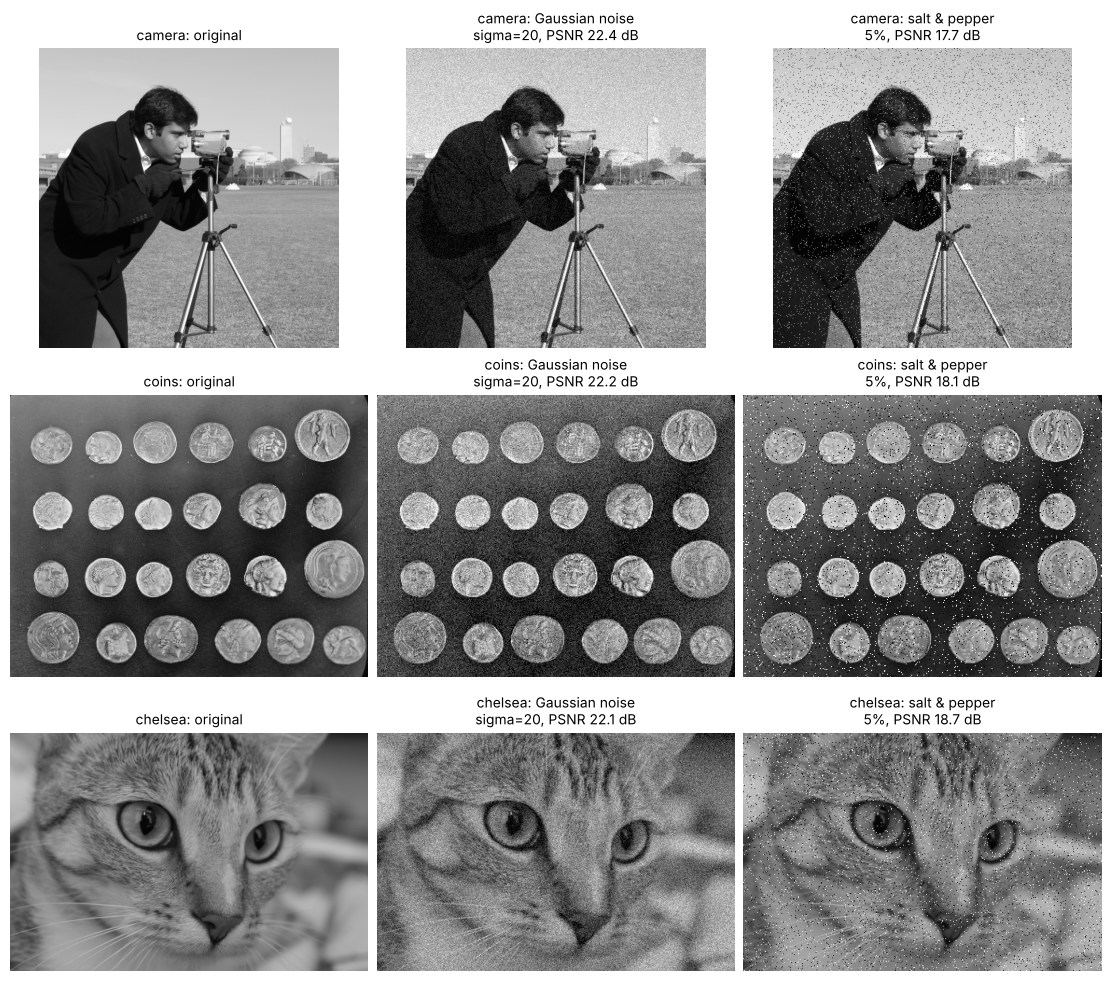

In [5]:
# Labelled grid: original | Gaussian noise | salt & pepper, for each of the three images
fig, axes = plt.subplots(3, 3, figsize=(11, 10), layout="constrained")
for r, (n, orig) in enumerate(ORIGINALS.items()):
    panels = [(orig, f"{n}: original"),
              (NOISY[(n, "gauss")], f"{n}: Gaussian noise\nsigma=20, PSNR {psnr(orig, NOISY[(n, 'gauss')]):.1f} dB"),
              (NOISY[(n, "sp")], f"{n}: salt & pepper\n5%, PSNR {psnr(orig, NOISY[(n, 'sp')]):.1f} dB")]
    for c, (im, title) in enumerate(panels):
        axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(title, fontsize=10); axes[r, c].axis("off")
fig.savefig("figures/noise_grid.png", dpi=110, bbox_inches="tight")
plt.show()

## 5. Kernels and filters
* **Mean:** all weights `1/size²` → sum = 1 (R3). Applied once with `conv2d_loop`, then with `cv.blur`.
* **Gaussian:** discrete Gaussian weights from `cv.getGaussianKernel(size, 0)` (outer product of the 1-D kernel). At 3×3 this is exactly the **1-2-1 ÷ 16** kernel. Applied with `cv.GaussianBlur`.
* **Median:** the middle value of the sorted neighbourhood, via `cv.medianBlur`; even sizes are rejected (R4).

Every smoothing kernel's weight sum is printed and asserted equal to 1 **before** it is used (R3).

In [6]:
def mean_kernel(k):
    k = check_ksize(k)
    return np.full((k, k), 1.0 / (k * k))

def gaussian_kernel(k):
    k = check_ksize(k)
    g = cv.getGaussianKernel(k, 0)                 # 1-D weights, sigma derived from the size
    return g @ g.T                                 # separable -> 2-D

def require_unit_sum(name, kernel):
    s = kernel.sum()
    print(f"  {name:<14s} weight sum = {s:.12f}")
    assert abs(s - 1.0) < 1e-12, f"{name}: weights do not sum to 1!"

print("R3 - weight sums:")
for k in (3, 5, 7):
    require_unit_sum(f"mean {k}x{k}", mean_kernel(k))
    require_unit_sum(f"gaussian {k}x{k}", gaussian_kernel(k))

print("\nGaussian 3x3 weights x 16 :\n", np.rint(gaussian_kernel(3) * 16).astype(int))
print("Gaussian 5x5 weights x 256:\n", np.rint(gaussian_kernel(5) * 256).astype(int))
print("Gaussian 7x7 weights x 1000 (not a binomial kernel, OpenCV's own 7-tap):\n", np.round(gaussian_kernel(7) * 1000, 1))

R3 - weight sums:
  mean 3x3       weight sum = 1.000000000000
  gaussian 3x3   weight sum = 1.000000000000
  mean 5x5       weight sum = 1.000000000000
  gaussian 5x5   weight sum = 1.000000000000
  mean 7x7       weight sum = 1.000000000000
  gaussian 7x7   weight sum = 1.000000000000

Gaussian 3x3 weights x 16 :
 [[1 2 1]
 [2 4 2]
 [1 2 1]]
Gaussian 5x5 weights x 256:
 [[ 1  4  6  4  1]
 [ 4 16 24 16  4]
 [ 6 24 36 24  6]
 [ 4 16 24 16  4]
 [ 1  4  6  4  1]]
Gaussian 7x7 weights x 1000 (not a binomial kernel, OpenCV's own 7-tap):
 [[ 1.   3.4  6.8  8.8  6.8  3.4  1. ]
 [ 3.4 12.  23.9 30.8 23.9 12.   3.4]
 [ 6.8 23.9 47.9 61.5 47.9 23.9  6.8]
 [ 8.8 30.8 61.5 79.1 61.5 30.8  8.8]
 [ 6.8 23.9 47.9 61.5 47.9 23.9  6.8]
 [ 3.4 12.  23.9 30.8 23.9 12.   3.4]
 [ 1.   3.4  6.8  8.8  6.8  3.4  1. ]]


In [7]:
def mean_filter_loop(img, k):                      # own convolution
    return to_uint8(conv2d_loop(img, mean_kernel(k)))

def mean_filter(img, k):                           # fast OpenCV version
    return cv.blur(img, (check_ksize(k), check_ksize(k)), borderType=cv.BORDER_REFLECT_101)

def gaussian_filter(img, k):
    k = check_ksize(k)
    return cv.GaussianBlur(img, (k, k), 0, borderType=cv.BORDER_REFLECT_101)

def median_filter(img, k):
    return cv.medianBlur(img, check_ksize(k))      # R4: even / unsupported sizes rejected

FILTERS = {"mean": mean_filter, "gaussian": gaussian_filter, "median": median_filter}

# ---- own loop vs cv.blur for the mean filter (one real image, all three sizes) ----
print("Mean filter: conv2d_loop vs cv.blur on 'camera' (uint8 outputs):")
rows = []
for k in (3, 5, 7):
    a, b = mean_filter_loop(cam, k), mean_filter(cam, k)
    diff = np.abs(a.astype(int) - b.astype(int))
    rows.append((f"{k}x{k}", int(diff.max()), f"{np.mean(diff == 0) * 100:.3f} %"))
    assert diff.max() <= 1
show_table(["Kernel", "Largest difference (grey levels)", "Pixels exactly equal"], rows)
VERIFY["mean_rows"] = rows

# ---- own loop on EVERY noisy image at 3x3 vs cv.blur ----
mx = 0
for key, im in NOISY.items():
    mx = max(mx, int(np.abs(mean_filter_loop(im, 3).astype(int) - mean_filter(im, 3).astype(int)).max()))
print(f"Largest difference between conv2d_loop and cv.blur over all 6 noisy images (3x3): {mx} grey level(s)")
# ---- own loop vs cv.GaussianBlur ----
g_loop = to_uint8(conv2d_loop(cam, gaussian_kernel(3))); g_cv = gaussian_filter(cam, 3)
print("Gaussian 3x3: conv2d_loop vs cv.GaussianBlur largest difference:", int(np.abs(g_loop.astype(int) - g_cv.astype(int)).max()))

Mean filter: conv2d_loop vs cv.blur on 'camera' (uint8 outputs):


| Kernel | Largest difference (grey levels) | Pixels exactly equal |
|---|---|---|
| 3x3 | 0 | 100.000 % |
| 5x5 | 0 | 100.000 % |
| 7x7 | 0 | 100.000 % |

Largest difference between conv2d_loop and cv.blur over all 6 noisy images (3x3): 0 grey level(s)


Gaussian 3x3: conv2d_loop vs cv.GaussianBlur largest difference: 1


## 6. Filtering every noisy image at 3×3 (judged against the clean original — R6)

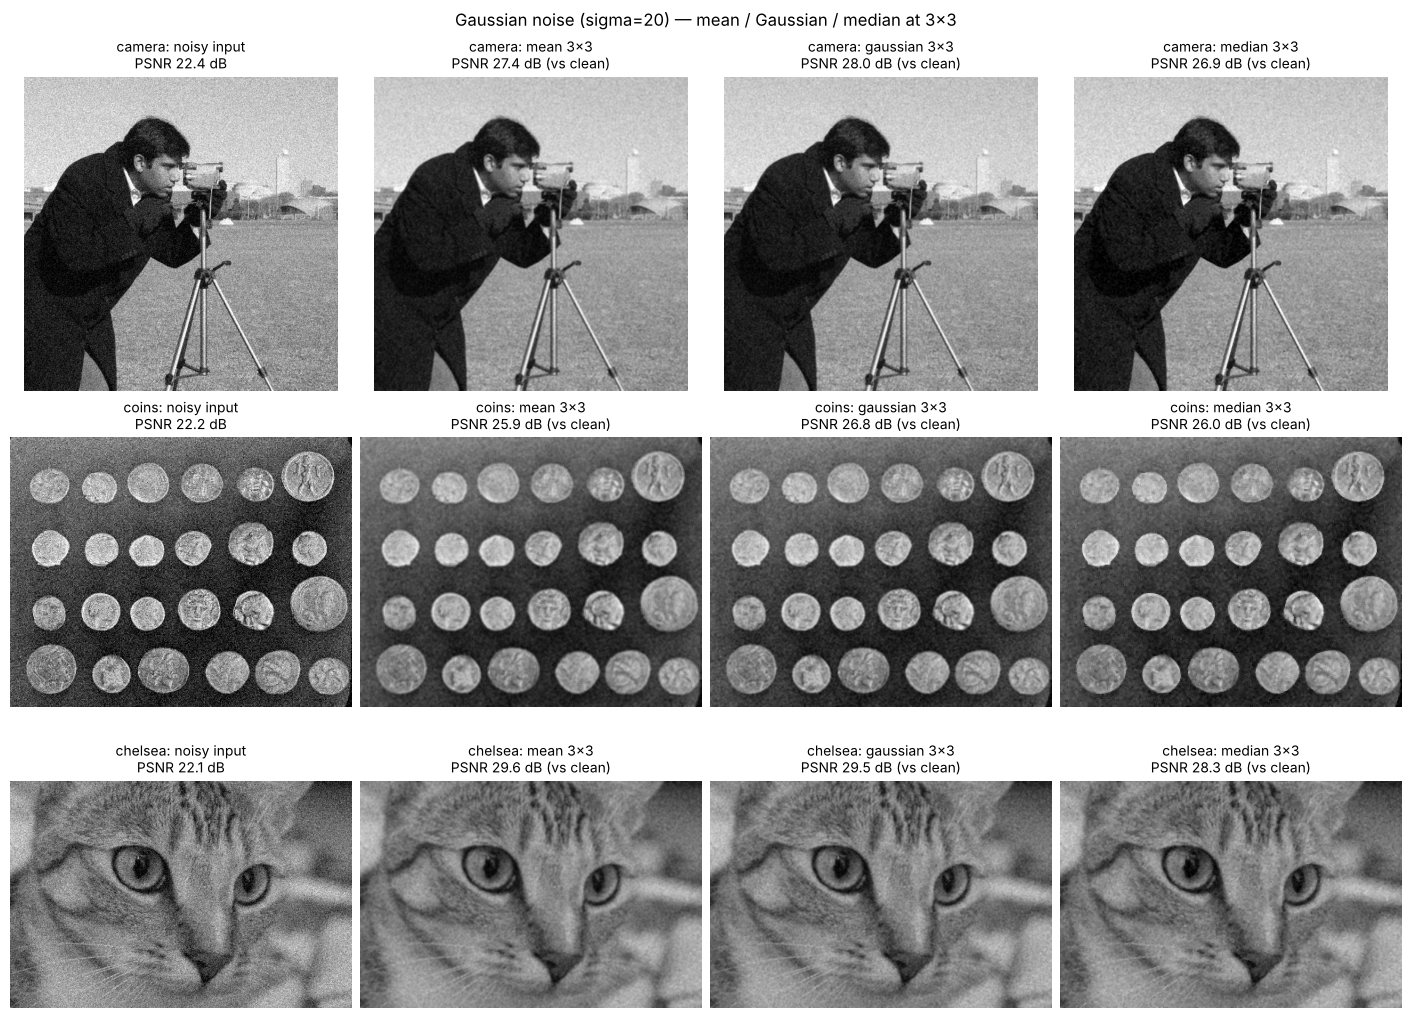

In [8]:
def score(clean, out):
    return psnr(clean, out), float(np.mean(np.abs(clean.astype(int) - out.astype(int))))

RESULTS = {}      # (image, noise, filter, k) -> uint8 output
for (n, kind), noisy in NOISY.items():
    for fname, f in FILTERS.items():
        for k in (3, 5, 7):
            RESULTS[(n, kind, fname, k)] = f(noisy, k)

def filter_grid(kind, k, fname_png):
    fig, axes = plt.subplots(3, 4, figsize=(14, 10.5), layout="constrained")
    for r, n in enumerate(ORIGINALS):
        clean, noisy = ORIGINALS[n], NOISY[(n, kind)]
        axes[r, 0].imshow(noisy, cmap="gray", vmin=0, vmax=255)
        axes[r, 0].set_title(f"{n}: noisy input\nPSNR {psnr(clean, noisy):.1f} dB", fontsize=10)
        for c, fname in enumerate(FILTERS, start=1):
            out = RESULTS[(n, kind, fname, k)]
            axes[r, c].imshow(out, cmap="gray", vmin=0, vmax=255)
            axes[r, c].set_title(f"{n}: {fname} {k}x{k}\nPSNR {psnr(clean, out):.1f} dB (vs clean)", fontsize=10)
        for ax in axes[r]: ax.axis("off")
    fig.suptitle(f"{KIND_NAME[kind]} — mean / Gaussian / median at {k}x{k}", fontsize=12)
    fig.savefig(f"figures/{fname_png}", dpi=110, bbox_inches="tight")
    plt.show()

filter_grid("gauss", 3, "filters_gaussian_noise_3x3.png")

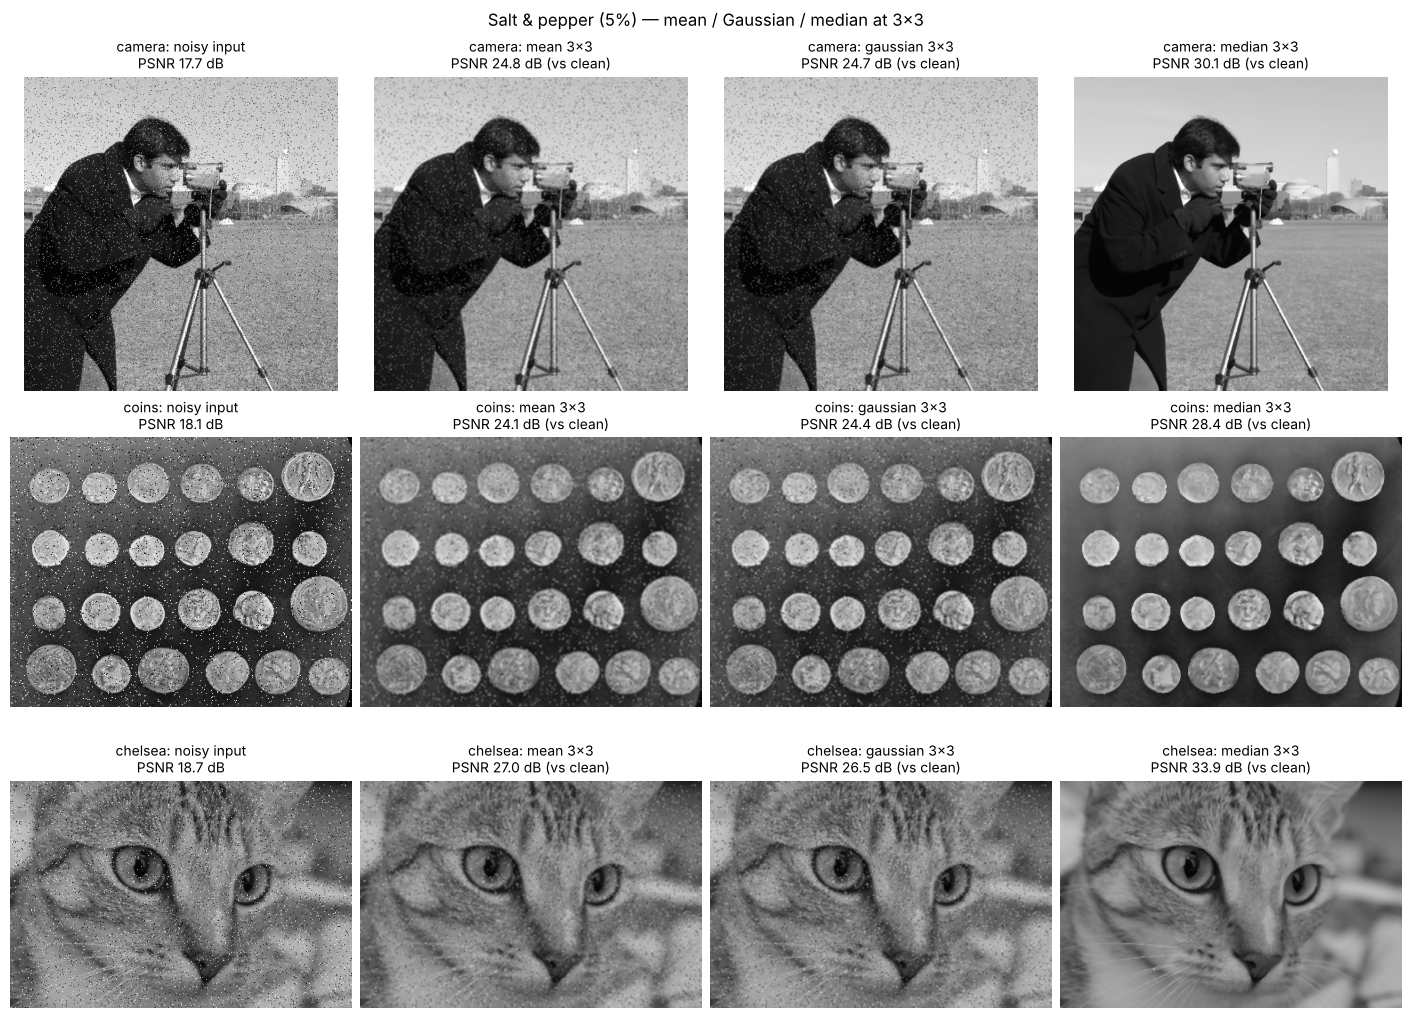

In [9]:
filter_grid("sp", 3, "filters_saltpepper_noise_3x3.png")

In [10]:
rows = []
for (n, kind), noisy in NOISY.items():
    row = [n, KIND_NAME[kind], f"{psnr(ORIGINALS[n], noisy):.2f}"]
    for fname in FILTERS:
        p, m = score(ORIGINALS[n], RESULTS[(n, kind, fname, 3)])
        row.append(f"{p:.2f} / {m:.2f}")
    rows.append(row)
show_table(["Image", "Noise", "Noisy PSNR (dB)", "Mean 3x3  PSNR / MAE", "Gaussian 3x3  PSNR / MAE", "Median 3x3  PSNR / MAE"], rows)
print("All numbers compare the filtered image with the CLEAN original (R6); higher PSNR / lower MAE is better.")

| Image | Noise | Noisy PSNR (dB) | Mean 3x3  PSNR / MAE | Gaussian 3x3  PSNR / MAE | Median 3x3  PSNR / MAE |
|---|---|---|---|---|---|
| camera | Gaussian noise (sigma=20) | 22.40 | 27.37 / 7.81 | 27.99 / 7.63 | 26.95 / 8.50 |
| camera | Salt & pepper (5%) | 17.69 | 24.83 / 9.12 | 24.71 / 8.51 | 30.12 / 3.53 |
| coins | Gaussian noise (sigma=20) | 22.20 | 25.86 / 8.95 | 26.79 / 8.49 | 26.00 / 9.31 |
| coins | Salt & pepper (5%) | 18.11 | 24.10 / 10.40 | 24.36 / 9.49 | 28.37 / 4.81 |
| chelsea | Gaussian noise (sigma=20) | 22.12 | 29.55 / 6.55 | 29.46 / 6.75 | 28.28 / 7.65 |
| chelsea | Salt & pepper (5%) | 18.73 | 27.00 / 7.55 | 26.50 / 7.27 | 33.94 / 2.52 |

All numbers compare the filtered image with the CLEAN original (R6); higher PSNR / lower MAE is better.


## 7. Kernel size: 3×3 vs 5×5 vs 7×7 on the noisiest image
The *noisiest* image is the one with the lowest PSNR against its clean original.

Noisiest image: camera with Salt & pepper (5%) (PSNR 17.69 dB)


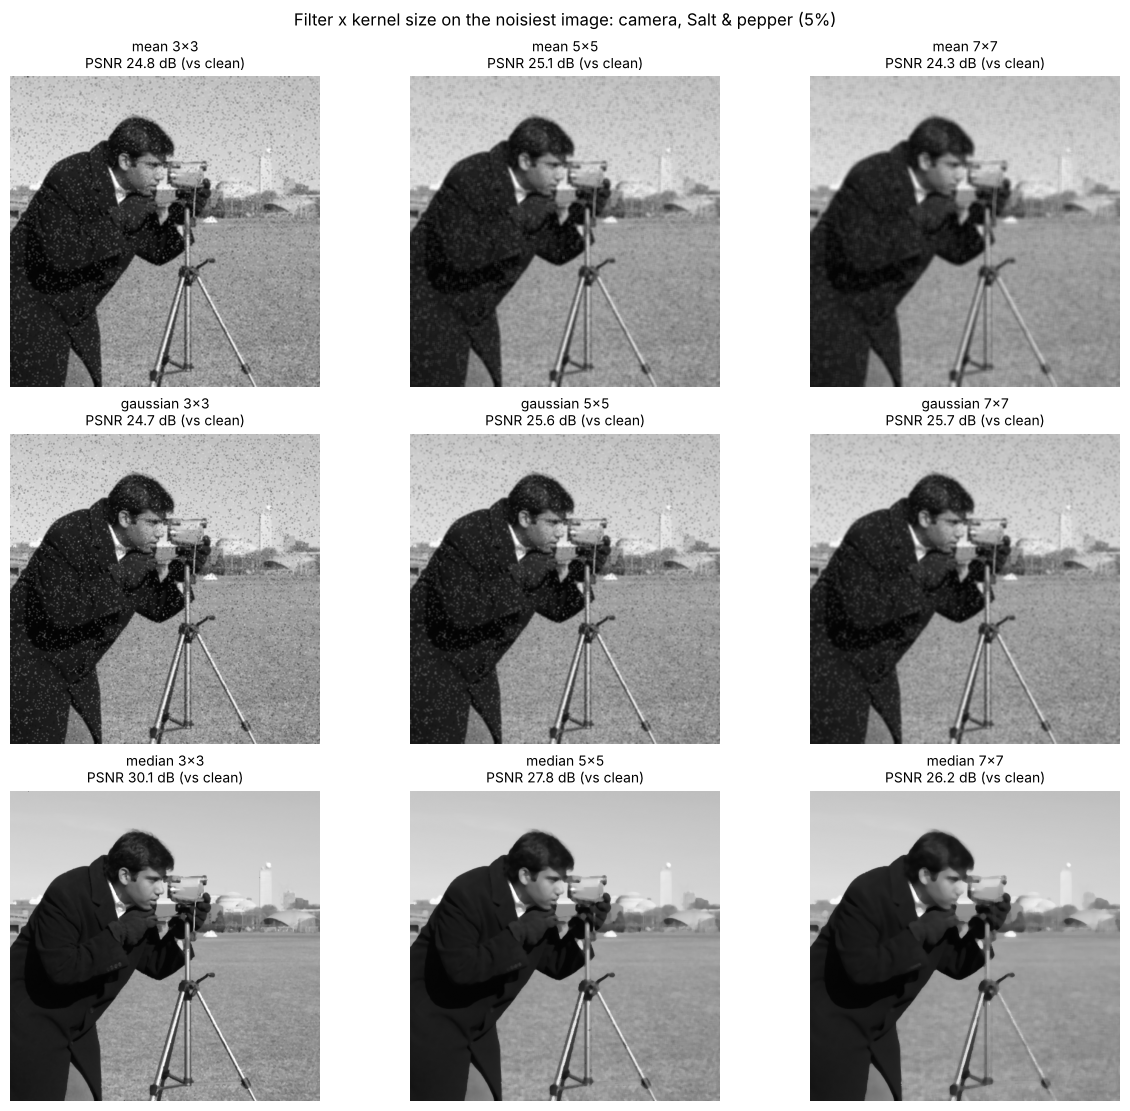

| Filter | 3x3 PSNR / MAE | 5x5 PSNR / MAE | 7x7 PSNR / MAE |
|---|---|---|---|
| mean | 24.83 / 9.12 | 25.09 / 9.49 | 24.25 / 10.04 |
| gaussian | 24.71 / 8.51 | 25.65 / 8.58 | 25.67 / 8.85 |
| median | 30.12 / 3.53 | 27.84 / 4.83 | 26.23 / 5.78 |

In [11]:
noisy_rank = sorted(((psnr(ORIGINALS[n], im), n, kind) for (n, kind), im in NOISY.items()))
p_worst, n_worst, kind_worst = noisy_rank[0]
print(f"Noisiest image: {n_worst} with {KIND_NAME[kind_worst]} (PSNR {p_worst:.2f} dB)")
clean, noisy = ORIGINALS[n_worst], NOISY[(n_worst, kind_worst)]

fig, axes = plt.subplots(3, 3, figsize=(12, 11), layout="constrained")
for r, fname in enumerate(FILTERS):
    for c, k in enumerate((3, 5, 7)):
        out = RESULTS[(n_worst, kind_worst, fname, k)]
        axes[r, c].imshow(out, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{fname} {k}x{k}\nPSNR {psnr(clean, out):.1f} dB (vs clean)", fontsize=10)
        axes[r, c].axis("off")
fig.suptitle(f"Filter x kernel size on the noisiest image: {n_worst}, {KIND_NAME[kind_worst]}", fontsize=12)
fig.savefig("figures/kernel_size_grid.png", dpi=110, bbox_inches="tight")
plt.show()

rows = []
for fname in FILTERS:
    rows.append([fname] + [f"{psnr(clean, RESULTS[(n_worst, kind_worst, fname, k)]):.2f} / {np.mean(np.abs(clean.astype(int) - RESULTS[(n_worst, kind_worst, fname, k)].astype(int))):.2f}" for k in (3, 5, 7)])
show_table(["Filter", "3x3 PSNR / MAE", "5x5 PSNR / MAE", "7x7 PSNR / MAE"], rows)

## 8. Rule compliance checks (R1–R5)

In [12]:
# ---- R1 / R2: dtype, range and shape of every filtered output ----
bad = 0
for (n, kind, fname, k), out in RESULTS.items():
    src = NOISY[(n, kind)]
    ok = out.dtype == np.uint8 and out.min() >= 0 and out.max() <= 255 and out.shape == src.shape
    bad += (not ok)
print(f"R1/R2: checked {len(RESULTS)} filtered outputs -> dtype uint8, values within 0-255, shape == input shape: "
      f"{'ALL OK' if bad == 0 else str(bad) + ' FAILED'}")
print("       conv2d_loop returns:", conv2d_loop(ORIGINALS['coins'][:20, :20], mean_kernel(3)).dtype, "(float64, same size)")
assert bad == 0

# ---- R3: weight sums were printed and asserted in Section 5 ----
print("R3: mean and Gaussian kernel sums were printed and asserted == 1 in Section 5; a flat region keeps its brightness:")
flat = np.full((9, 9), 123, dtype=np.uint8)
print("    flat 123 -> mean 7x7 gives", np.unique(mean_filter(flat, 7)), "| gaussian 7x7 gives", np.unique(gaussian_filter(flat, 7)))

# ---- R4: even / unsupported kernel sizes are rejected ----
print("R4: OpenCV rejects an even median size:")
try:
    cv.medianBlur(ORIGINALS["camera"], 4)
except cv.error as e:
    print("    cv2.medianBlur(img, 4) raised cv2.error ->", str(e).strip().splitlines()[-1][:110])
for bad_k in (4, 2, 6, 9, "3"):
    try:
        median_filter(ORIGINALS["camera"], bad_k)
    except ValueError as e:
        print(f"    median_filter(img, {bad_k!r}) -> ValueError: {e}")

# ---- R5: regenerate the noise on a 'fresh run' with seed=5 and compare ----
NOISY2 = make_noisy()
same = all(np.array_equal(NOISY[k], NOISY2[k]) for k in NOISY)
print("R5: regenerated all 6 noisy images with seed=5 ->", "IDENTICAL (np.array_equal is True for all)" if same else "DIFFERENT!")
print("    a different seed gives a different image:", not np.array_equal(add_gaussian_noise(ORIGINALS['coins'], seed=6), NOISY[('coins', 'gauss')]))
assert same

R1/R2: checked 54 filtered outputs -> dtype uint8, values within 0-255, shape == input shape: ALL OK
       conv2d_loop returns: float64 (float64, same size)
R3: mean and Gaussian kernel sums were printed and asserted == 1 in Section 5; a flat region keeps its brightness:
    flat 123 -> mean 7x7 gives [123] | gaussian 7x7 gives [123]
R4: OpenCV rejects an even median size:
    cv2.medianBlur(img, 4) raised cv2.error -> OpenCV(5.0.0) /io/opencv/modules/imgproc/src/median_blur.dispatch.cpp:192: error: (-215:Assertion failed) (ksi
    median_filter(img, 4) -> ValueError: Kernel size must be 3, 5 or 7 (odd), got 4.
    median_filter(img, 2) -> ValueError: Kernel size must be 3, 5 or 7 (odd), got 2.
    median_filter(img, 6) -> ValueError: Kernel size must be 3, 5 or 7 (odd), got 6.
    median_filter(img, 9) -> ValueError: Kernel size must be 3, 5 or 7 (odd), got 9.
    median_filter(img, '3') -> ValueError: Kernel size must be 3, 5 or 7 (odd), got '3'.
R5: regenerated all 6 noisy images w

## 9. Dry-run exercises (calculated by hand, then confirmed by code)

### Exercise 1 — Spike response
Neighbourhood (centre = bright pixel 255):

```
[[ 40,  40,  40],
 [ 40, 255,  40],
 [ 40,  40,  40]]
```

**3×3 mean** (all weights 1/9): sum = 8 × 40 + 255 = 320 + 255 = **575** → 575 / 9 = 63.89 → **64**.

**3×3 Gaussian (1-2-1 ÷ 16)**, kernel `[[1,2,1],[2,4,2],[1,2,1]] / 16`:
* corners: 4 pixels × weight 1 × 40 = 160
* edges: 4 pixels × weight 2 × 40 = 320
* centre: 1 pixel × weight 4 × 255 = 1020
* total = 160 + 320 + 1020 = **1500** → 1500 / 16 = 93.75 → **94**.
(The weights sum to 1 + 2 + 1 + 2 + 4 + 2 + 1 + 2 + 1 = 16, which is why we divide by 16 so that they total 1.)

**3×3 median:** sorted values = 40, 40, 40, 40, 40, 40, 40, 40, 255 → the middle (5th) value is **40**.

The mean and Gaussian leak part of the spike into the output (64 and 94 against a true background of 40), the median ignores it completely.

In [13]:
w1 = np.array([[40, 40, 40], [40, 255, 40], [40, 40, 40]], dtype=np.float64)
g16 = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16
mean_c = np.sum(w1 * mean_kernel(3));  gauss_c = np.sum(w1 * g16);  med_c = np.median(w1)
print(f"mean sum = {np.sum(w1):.0f} -> {np.sum(w1) / 9:.4f} -> {int(np.rint(mean_c))}")
print(f"gaussian weighted sum x16 = {np.sum(w1 * np.array([[1,2,1],[2,4,2],[1,2,1]])):.0f} -> {gauss_c:.4f} -> {int(np.rint(gauss_c))}")
print(f"median = {med_c:.0f}")
# the same numbers through the notebook's own conv2d_loop (centre pixel) and OpenCV
print("conv2d_loop centre:  mean", round(conv2d_loop(w1, mean_kernel(3))[1, 1], 4), "| gaussian", round(conv2d_loop(w1, g16)[1, 1], 4))
w1u = w1.astype(np.uint8)
print("OpenCV centre:       mean", cv.blur(w1u, (3, 3))[1, 1], "| gaussian", cv.GaussianBlur(w1u, (3, 3), 0)[1, 1], "| median", cv.medianBlur(w1u, 3)[1, 1])
assert (int(np.rint(mean_c)), int(np.rint(gauss_c)), med_c) == (64, 94, 40)

mean sum = 575 -> 63.8889 -> 64
gaussian weighted sum x16 = 1500 -> 93.7500 -> 94
median = 40
conv2d_loop centre:  mean 63.8889 | gaussian 93.75
OpenCV centre:       mean 64 | gaussian 94 | median 40


### Exercise 2 — Reflect padding at a corner
Image:

```
[[10, 20, 30],
 [40, 50, 60],
 [70, 80, 90]]
```

NumPy `mode="reflect"` mirrors **about the edge pixel without repeating it**, so index −1 maps to index 1. For pixel (0, 0) the rows used are (1, 0, 1) and the columns used are (1, 0, 1). The padded 3×3 neighbourhood that is averaged is:

```
[[50, 40, 50],
 [20, 10, 20],
 [50, 40, 50]]
```

Sum = (50 + 40 + 50) + (20 + 10 + 20) + (50 + 40 + 50) = 140 + 50 + 140 = **330** → 330 / 9 = 36.67 → **37**.

In [14]:
img2 = np.array([[10, 20, 30], [40, 50, 60], [70, 80, 90]], dtype=np.float64)
pad2 = np.pad(img2, 1, mode="reflect")
print("padded image (reflect):\n", pad2.astype(int))
nb = pad2[0:3, 0:3]                                   # neighbourhood of pixel (0, 0)
print("neighbourhood of (0,0):\n", nb.astype(int), "\nsum =", nb.sum(), " mean =", round(nb.sum() / 9, 4), "-> rounds to", int(np.rint(nb.sum() / 9)))
print("conv2d_loop(0,0):", round(conv2d_loop(img2, mean_kernel(3))[0, 0], 4), "| cv.blur(0,0):", cv.blur(img2.astype(np.uint8), (3, 3), borderType=cv.BORDER_REFLECT_101)[0, 0])
assert nb.sum() == 330 and int(np.rint(nb.sum() / 9)) == 37

padded image (reflect):
 [[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]
neighbourhood of (0,0):
 [[50 40 50]
 [20 10 20]
 [50 40 50]] 
sum = 330.0  mean = 36.6667 -> rounds to 37
conv2d_loop(0,0): 36.6667 | cv.blur(0,0): 37


In [15]:
# Sharp-edge test on the CLEAN 'camera' image: how much edge strength survives each smoothing filter?
f = ORIGINALS["camera"].astype(np.float64)
def grad_mag(a):
    a = a.astype(np.float64)
    return np.hypot(cv.Sobel(a, cv.CV_64F, 1, 0, ksize=3), cv.Sobel(a, cv.CV_64F, 0, 1, ksize=3))
edge_mask = grad_mag(f) > np.percentile(grad_mag(f), 95)          # strongest 5 % of edge pixels (coat, tripod legs, camera body)
base = grad_mag(f)[edge_mask].mean()
rows = [["original (clean)", f"{base:.0f}", "100 %"]]
for k in (3, 5, 7):
    for name, fn in (("mean", mean_filter), ("gaussian", gaussian_filter)):
        v = grad_mag(fn(ORIGINALS["camera"], k))[edge_mask].mean()
        rows.append([f"{name} {k}x{k}", f"{v:.0f}", f"{v / base * 100:.0f} %"])
show_table(["Image", "Mean gradient strength on the sharpest edges", "Edge strength kept"], rows)

| Image | Mean gradient strength on the sharpest edges | Edge strength kept |
|---|---|---|
| original (clean) | 358 | 100 % |
| mean 3x3 | 250 | 70 % |
| gaussian 3x3 | 275 | 77 % |
| mean 5x5 | 157 | 44 % |
| gaussian 5x5 | 229 | 64 % |
| mean 7x7 | 104 | 29 % |
| gaussian 7x7 | 179 | 50 % |

## 10. Observations (answered from the figures above)


**1. Gaussian noise — best and worst filter.** The **Gaussian 3×3** filter is best on `camera` (28.0 dB) and `coins` (26.8 dB); on `chelsea` mean and Gaussian are practically tied (29.6 vs 29.5 dB). The **median** is the worst in all three (26.9, 26.0 and 28.3 dB). Look at the grass in the lower half of `camera` in the Gaussian-noise grid: after mean/Gaussian the grain is smooth and even, while the median leaves a blotchy, slightly "painted" texture because it picks one of the noisy values instead of averaging them, and the random noise has no extreme outliers for the median to remove.

**2. Salt-and-pepper noise — best filter and why the other two fail.** The **median 3×3** is clearly best (30.1 dB on `camera`, 28.4 on `coins`, 33.9 on `chelsea`) and in its column of the salt-and-pepper grid the black and white dots are gone — e.g. the bright sky above the cameraman's head is clean. **Mean and Gaussian fail** (about 24–27 dB): in their columns the sky is still covered in dark dots, each one now a grey smudge. A 0 or 255 pixel is far from its neighbours, so a weighted *average* is pulled toward it (a single 255 among 40s gives 64 for the mean and 94 for the Gaussian in Dry-run 1) and the spike is spread over the neighbourhood instead of removed. The median sorts the window, so an extreme value ends up at the end of the list and is never selected.

**3. Mean vs Gaussian on a sharp edge.** On the clean `camera` image, measured on the strongest 5 % of edge pixels (the coat/sky boundary, the tripod legs, the camera body), a 3×3 **mean keeps 70 %** of the edge strength and a 3×3 **Gaussian keeps 77 %**; at 5×5 the gap widens to **44 % vs 64 %** (table above). The Gaussian gives the centre pixel the largest weight (4/16 against 1/9), so an edge is softened less. In the figures this shows on the thin tripod legs in the Gaussian-noise grid: they stay a little sharper after Gaussian than after mean. The mean treats a pixel across the edge exactly like the centre pixel, so edges spread more evenly into a wider ramp.

**4. Fine detail at 7×7.** In the kernel-size grid (`camera`, salt-and-pepper) the 7×7 results are visibly over-smoothed: the thin tripod legs turn into faint wide bands, the detail on the camera body and the building skyline at the horizon merge into grey, and the face becomes noticeably softer. The mean and Gaussian rows also barely improve: the 7×7 mean drops to 24.3 dB (below its 5×5 value of 25.1 dB) because the blur costs more than the extra noise averaging gains. The median falls steadily with size (30.1 → 27.8 → 26.2 dB): it already removed the noise at 3×3, so a larger window only rounds off corners and deletes thin structures narrower than half the window.

**5. Why the kernel size must be odd.** An odd kernel has a single **centre pixel**, so the output can be written back to exactly the position it was computed for, and the window extends the same distance (k//2) on every side. With an even size such as 4 there is no centre: the output would be shifted by half a pixel, padding would be unequal on the two sides, and the "middle" of a sorted list of 16 values for the median is undefined (two middle values). OpenCV enforces this — `cv2.medianBlur(img, 4)` raised an error in Section 8 — and our `check_ksize` rejects every size other than 3, 5 and 7.